<a href="https://colab.research.google.com/github/enslern/The-AI-engineer-course-2026-Complete-AI-bootcamp/blob/main/langgraph_message_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Graph with memory:Annotated messages**

##**setting the api key**

In [1]:
import sys,os

In [2]:
sys.path.append(os.path.abspath("/content/drive/MyDrive/Colab Notebooks/resources"))

In [3]:
import config

In [4]:
os.environ["GROQ_API_KEY"]=config.GROQ_API_KEY

##**Importing the relevant classes and function**

In [5]:

!pip install langchain==0.3.25
!pip install langgraph==0.4.8
!pip install langchain-groq
!pip install langgraph-checkpoint-sqlite==0.3.17
!pip install grandalf==0.8

  Using cached langgraph-0.4.8-py3-none-any.whl.metadata (6.8 kB)
  Using cached langchain_core-1.6.10-py3-none-any.whl.metadata (4.8 kB)
Using cached langgraph-0.4.8-py3-none-any.whl (152 kB)
Using cached langchain_core-1.6.10-py3-none-any.whl (573 kB)
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 0.3.86
    Uninstalling langchain-core-0.3.86:
      Successfully uninstalled langchain-core-0.3.86
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.12
    Uninstalling langgraph-1.2.12:
      Successfully uninstalled langgraph-1.2.12
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain 0.3.25 requires langchain-core<1.0.0,>=0.3.58, but you have langchain-core 1.6.10 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.9 MB/s eta 0:00:00
ERROR: Could not find 

In [6]:
from langgraph.graph import START,END,StateGraph,add_messages
from typing_extensions import TypedDict
from langchain_core.messages import AIMessage,HumanMessage,BaseMessage
from collections.abc import Sequence
from typing import Literal ,Annotated
from langchain_groq import ChatGroq

##**gettting familiar with add message function**

In [7]:
my_list=add_messages([],[HumanMessage("hi! my name is Oscar"),AIMessage("hello Oscar!, how can i assist you?"),HumanMessage("could you summarize today's news?")])

In [8]:
my_list

[HumanMessage(content='hi! my name is Oscar', additional_kwargs={}, response_metadata={}, id='febc889e-e793-4375-aa44-cf067445d044'),
 AIMessage(content='hello Oscar!, how can i assist you?', additional_kwargs={}, response_metadata={}, id='4237604c-d9ac-45f8-a14b-93094d816857', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="could you summarize today's news?", additional_kwargs={}, response_metadata={}, id='fea6407f-77f1-4832-82a1-2f5fbac531fd')]

##**define the state**

In [9]:
class State(TypedDict):
  messages:Annotated[Sequence[BaseMessage],add_messages]

##**define the nodes**

In [10]:
chat=ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    seed=365,
    max_tokens=300,
    reasoning_format="hidden",

)

/usr/local/lib/python3.13/dist-packages/pydantic/main.py:263: UserWarning: WARNING! seed is not default parameter.
                    seed was transferred to model_kwargs.
                    Please confirm that seed is what you intended.
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


In [11]:
def chatbot(state:State)->State:
  print(f"\n-------------> Entering chatbot")

  for i in state["messages"]:
    i.pretty_print()
  response=chat.invoke(state["messages"])
  response.pretty_print()
  return State(messages=[response])

In [12]:
def ask_question(state:State)->State:
  print(f"\n----------->Entering ask_question")

  for i in state["messages"]:
    i.pretty_print()
  question="what is your questionn?"
  print(question)

  return State(messages=[AIMessage(question),HumanMessage(input())])

In [13]:
def ask_another_question(state:State)->State:
  print(f"\n---------->Entering ask_another_question")

  for i in state["messages"]:
    i.pretty_print()

  question=f"do you want to continue? (yes/no)"
  print(question)
  return State(messages=[AIMessage(question),HumanMessage(input())])

In [14]:
def routing_function(state:State)->Literal["ask_question","__end__"]:
  if state["messages"][-1].content=="yes":
    return "ask_question"
  else:
    return "__end__"

##**defining the graph**

In [15]:
graph=StateGraph(State)
graph.add_node(chatbot)
graph.add_node(ask_question)
graph.add_node(ask_another_question)
graph.add_edge(START,"ask_question")
graph.add_edge("ask_question","chatbot")
graph.add_edge("chatbot","ask_another_question")
graph.add_conditional_edges(source="ask_another_question",path=routing_function)

In [16]:
graph_compiled=graph.compile()

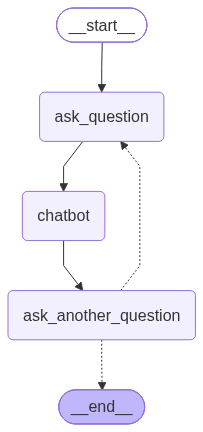

In [17]:
graph_compiled

##**testing the graph**

In [18]:
graph_compiled.invoke(State(messages=[]))


----------->Entering ask_question
what is your questionn?


KeyboardInterrupt: Interrupted by user

#**MessagesState class**

##**redefing all the nodes with the messagesstate class** **bold text**

In [19]:
from langgraph.graph import MessagesState

In [20]:
def chatbot(state:MessagesState)->MessagesState:
  print(f"\n-------------> Entering chatbot")

  for i in state["messages"]:
    i.pretty_print()
  response=chat.invoke(state["messages"])
  response.pretty_print()
  return MessagesState(messages=[response])


def ask_question(state:MessagesState)->MessagesState:
  print(f"\n----------->Entering ask_question")

  for i in state["messages"]:
    i.pretty_print()
  question="what is your questionn?"
  print(question)

  return MessagesState(messages=[AIMessage(question),HumanMessage(input())])

def ask_another_question(state:MessagesState)->MessagesState:
  print(f"\n---------->Entering ask_another_question")

  for i in state["messages"]:
    i.pretty_print()

  question=f"do you want to continue? (yes/no)"
  print(question)
  return MessagesState(messages=[AIMessage(question),HumanMessage(input())])

def routing_function(state:MessagesState)->Literal["ask_question","__end__"]:
  if state["messages"][-1].content=="yes":
    return "ask_question"
  else:
    return "__end__"


##**redefining the graph**

In [21]:
graph=StateGraph(MessagesState)
graph=StateGraph(State)
graph.add_node(chatbot)
graph.add_node(ask_question)
graph.add_node(ask_another_question)
graph.add_edge(START,"ask_question")
graph.add_edge("ask_question","chatbot")
graph.add_edge("chatbot","ask_another_question")
graph.add_conditional_edges(source="ask_another_question",path=routing_function)

In [22]:
graph_compiled=graph.compile()

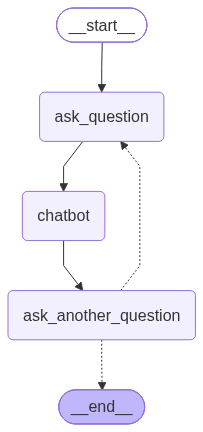

In [23]:
graph_compiled

In [24]:
graph_compiled.invoke(MessagesState(messages=[]))


----------->Entering ask_question
what is your questionn?


KeyboardInterrupt: Interrupted by user

#**RemoveMessages class**

###**getting started with remove messages class**

In [25]:
from langchain_core.messages import RemoveMessage

In [26]:
my_list=add_messages([],[HumanMessage("hello im oscar"),
                      AIMessage("hello oscar! how can i assist you?"),
                      HumanMessage("lick my shoes"),
                      AIMessage("i cant do that physically for you u mf  , ask ur mom for that")])

In [27]:
remove_list=[RemoveMessage(id=i.id) for i in my_list[:-2]]

In [28]:
remove_list

[RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='02942a58-cc00-4526-a828-7ed8c38a29cb'),
 RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='14f408de-0f3f-4ad5-8e31-e61c43e1bc7b')]

In [29]:
add_messages(my_list,remove_list)

[HumanMessage(content='lick my shoes', additional_kwargs={}, response_metadata={}, id='efc89a4c-73c4-4252-a71e-db878768e13b'),
 AIMessage(content='i cant do that physically for you u mf  , ask ur mom for that', additional_kwargs={}, response_metadata={}, id='92957be5-e4a2-40f5-a66c-7013ee8433c4', tool_calls=[], invalid_tool_calls=[])]

##**adding a new node to trim the messages and redefining the routing function**

In [42]:
def trim_messages(state:MessagesState)->MessagesState:
  print(f"\n--------->Entering trim_messages:")
  remove_messages=[RemoveMessage(id=i.id) for i in state["messages"][:-5]]
  return MessagesState(messages=remove_messages)

In [43]:
def routing_function(state:MessagesState)->Literal["trim_messages","__end__"]:
  if state["messages"][-1].content=="yes":
    return "trim_messages"
  else:
    return "__end__"

In [44]:
graph=StateGraph(MessagesState)
graph.add_node(chatbot)
graph.add_node(trim_messages)
graph.add_node(ask_question)
graph.add_node(ask_another_question)


graph.add_edge(START,"ask_question")
graph.add_edge("ask_question","chatbot")
graph.add_edge("chatbot","ask_another_question")
graph.add_edge("trim_messages","ask_question")
graph.add_conditional_edges(source="ask_another_question",path=routing_function)



In [45]:
graph_compiled=graph.compile()

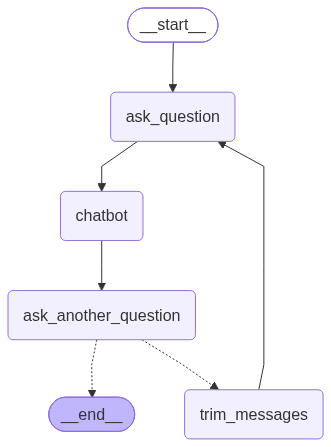

In [46]:
graph_compiled

In [47]:
graph_compiled.invoke(MessagesState(messages=[]))


----------->Entering ask_question
what is your questionn?
who is the pm of india?

-------------> Entering chatbot
================================== Ai Message ==================================

what is your questionn?
================================ Human Message =================================

who is the pm of india?
================================== Ai Message ==================================

The Prime Minister of India is **Narendra Modi**. He has been in office since May 26 2021, following his re‑election in the 2019 general election.

---------->Entering ask_another_question
================================== Ai Message ==================================

what is your questionn?
================================ Human Message =================================

who is the pm of india?
================================== Ai Message ==================================

The Prime Minister of India is **Narendra Modi**. He has been in office since May 26 2021, following his re

{'messages': [AIMessage(content='what is your questionn?', additional_kwargs={}, response_metadata={}, id='658bbcd9-a525-422a-8d3f-1f31fa0b2209', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='who is his wife?', additional_kwargs={}, response_metadata={}, id='bbfb5f7d-6fa8-4df7-abf1-44c9bc423efc'),
  AIMessage(content='Narendra\u202fModi does not have a wife. He has remained unmarried throughout his public and political life. While there have been occasional rumors and speculation in the media, Modi himself has never confirmed having a spouse, and official biographical sources list his marital status as “single.”', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 110, 'prompt_tokens': 207, 'total_tokens': 317, 'completion_time': 0.230634963, 'completion_tokens_details': {'reasoning_tokens': 45}, 'prompt_time': 0.00914745, 'prompt_tokens_details': None, 'queue_time': 0.171383958, 'total_time': 0.239782413}, 'model_name': 'openai/gpt-oss-120b'